In [8]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Task
Load the 'divar_dataset.csv' file, identify numeric columns, then calculate and visualize outliers using both Z-score and IQR methods, finally summarize the findings.

## Load Dataset

### Subtask:
Load the 'divar_dataset.csv' file into a pandas DataFrame.


**Reasoning**:
To load the 'divar_dataset.csv' file, I need to first import the pandas library and then use its `read_csv` function. Displaying the head of the DataFrame will confirm successful loading.



In [1]:
import pandas as pd

df = pd.read_csv('divar_dataset.csv')
print("DataFrame 'df' loaded successfully. Displaying the first 5 rows:")
print(df.head())

DataFrame 'df' loaded successfully. Displaying the first 5 rows:
      token                          url  \
0  QaURumLC  https://divar.ir/v/QaURumLC   
1  QaogCJMy  https://divar.ir/v/QaogCJMy   
2  QaAdBA-z  https://divar.ir/v/QaAdBA-z   
3  Qav0AhD9  https://divar.ir/v/Qav0AhD9   
4  QatkG3b9  https://divar.ir/v/QatkG3b9   

                                               title  \
0  فروش اپارتمان 125متری __دو خواب__نوساز خوارزم ...   
1  فروش شهرک غرب_115 متر 2 خواب_ 5ساله_لابی_ در ت...   
2  فروش 210 متر 2 p تک واحد شاهکار مهندسی شهرک غر...   
3  فروش (شهرک غرب دادمان)125متر 3خ_فول امکانات_ ک...   
4  فروش 150متر« دید ابدی مدرن شخصی»شهرک غرب در ته...   

                                         description       category  \
0  فروش فوری \n\nاپارتمان 125متری\n\nتکواحدی\n\nد...  فروش آپارتمان   
1  **خداوند یه خونه خوب بهتون هدیه بده**\n\nشهرک ...  فروش آپارتمان   
2  ALIREZA_GHASEMI\n\nبا سلام و احترام\n\n# فایل ...  فروش آپارتمان   
3  **فایل کاملا شخصی و واقعی میباشد !! \n✅بازدید 

## Identify Numeric Columns

### Subtask:
Identify all numeric columns within the loaded dataset to prepare for outlier detection.


**Reasoning**:
To identify numeric columns, I will use the `select_dtypes(include='number')` method on the DataFrame `df`, then extract and print their names.



In [2]:
numeric_cols = df.select_dtypes(include='number').columns.tolist()
print("Identified numeric columns:")
print(numeric_cols)

Identified numeric columns:
['city_id', 'price_total', 'area_m2', 'rooms', 'unit_condition', 'direction', 'has_balcony', 'lat', 'lng', 'location_radius', 'image_count']


## Calculate Z-scores and Detect Outliers

### Subtask:
For each numeric column, calculate the Z-score and identify outliers based on a defined threshold (e.g., |Z-score| > 3).


**Reasoning**:
To calculate Z-scores and identify outliers, I need to import the `stats` module from `scipy` and `numpy`. I will then iterate through the numeric columns, calculate Z-scores, and store the identified outliers in a dictionary, finally printing the count of outliers for each column.



In [3]:
import numpy as np
from scipy import stats

zscore_outliers_dict = {}

print("\n--- Z-score Outlier Detection (Threshold: |Z-score| > 3) ---")

for col in numeric_cols:
    # Drop NaN values for accurate Z-score calculation
    clean_data = df[col].dropna()
    if not clean_data.empty:
        # Calculate Z-scores
        z_scores = np.abs(stats.zscore(clean_data))

        # Identify outliers based on threshold
        outliers = clean_data[z_scores > 3.0]

        if not outliers.empty:
            zscore_outliers_dict[col] = outliers
            print(f"Column '{col}': {len(outliers)} outliers found.")
        else:
            print(f"Column '{col}': No outliers found.")
    else:
        print(f"Column '{col}': No data to analyze (all NaN values).")



--- Z-score Outlier Detection (Threshold: |Z-score| > 3) ---
Column 'city_id': No outliers found.
Column 'price_total': 3 outliers found.
Column 'area_m2': 3 outliers found.
Column 'rooms': No outliers found.
Column 'unit_condition': No data to analyze (all NaN values).
Column 'direction': No data to analyze (all NaN values).
Column 'has_balcony': No data to analyze (all NaN values).
Column 'lat': No outliers found.
Column 'lng': No outliers found.
Column 'location_radius': No outliers found.
Column 'image_count': 5 outliers found.


/tmp/ipython-input-1060625240.py:13: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  z_scores = np.abs(stats.zscore(clean_data))
/tmp/ipython-input-1060625240.py:13: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  z_scores = np.abs(stats.zscore(clean_data))


**Reasoning**:
The previous step successfully calculated Z-scores and identified outliers, though with a RuntimeWarning that does not prevent the next logical step. The next instruction is to calculate outliers using the IQR method. I will add a new subtask and a code block to implement the IQR outlier detection.



## Calculate IQR and Detect Outliers

### Subtask:
#### For each numeric column, calculate the IQR (Interquartile Range) and identify outliers based on the 1.5 * IQR rule.

In [5]:
iqr_outliers_dict = {}

print("\n--- IQR Outlier Detection (Threshold: 1.5 * IQR) ---")

for col in numeric_cols:
    clean_data = df[col].dropna()
    if not clean_data.empty:
        Q1 = clean_data.quantile(0.25)
        Q3 = clean_data.quantile(0.75)
        IQR = Q3 - Q1

        # Define outlier bounds
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Identify outliers
        outliers = clean_data[(clean_data < lower_bound) | (clean_data > upper_bound)]

        if not outliers.empty:
            iqr_outliers_dict[col] = outliers
            print(f"Column '{col}': {len(outliers)} outliers found.")
        else:
            print(f"Column '{col}': No outliers found.")
    else:
        print(f"Column '{col}': No data to analyze (all NaN values).")


--- IQR Outlier Detection (Threshold: 1.5 * IQR) ---
Column 'city_id': No outliers found.
Column 'price_total': 33 outliers found.
Column 'area_m2': 37 outliers found.
Column 'rooms': No outliers found.
Column 'unit_condition': No data to analyze (all NaN values).
Column 'direction': No data to analyze (all NaN values).
Column 'has_balcony': No data to analyze (all NaN values).
Column 'lat': No outliers found.
Column 'lng': No outliers found.
Column 'location_radius': No outliers found.
Column 'image_count': 11 outliers found.


## Visualize Outliers

### Subtask:
Visualize the outliers detected by both Z-score and IQR methods for selected numeric columns, for example, using box plots for IQR and scatter plots for Z-score with threshold lines. This will allow for a visual comparison of the detected outliers.



**Reasoning**:
Now that the subtask for visualizing outliers has been introduced, I will import the necessary plotting libraries and then generate box plots for columns like 'price_total' and 'area_m2', which were identified with outliers by both methods. This will visually represent the outliers detected by the IQR method.




--- Visualizing Outliers (Box Plots for IQR) ---


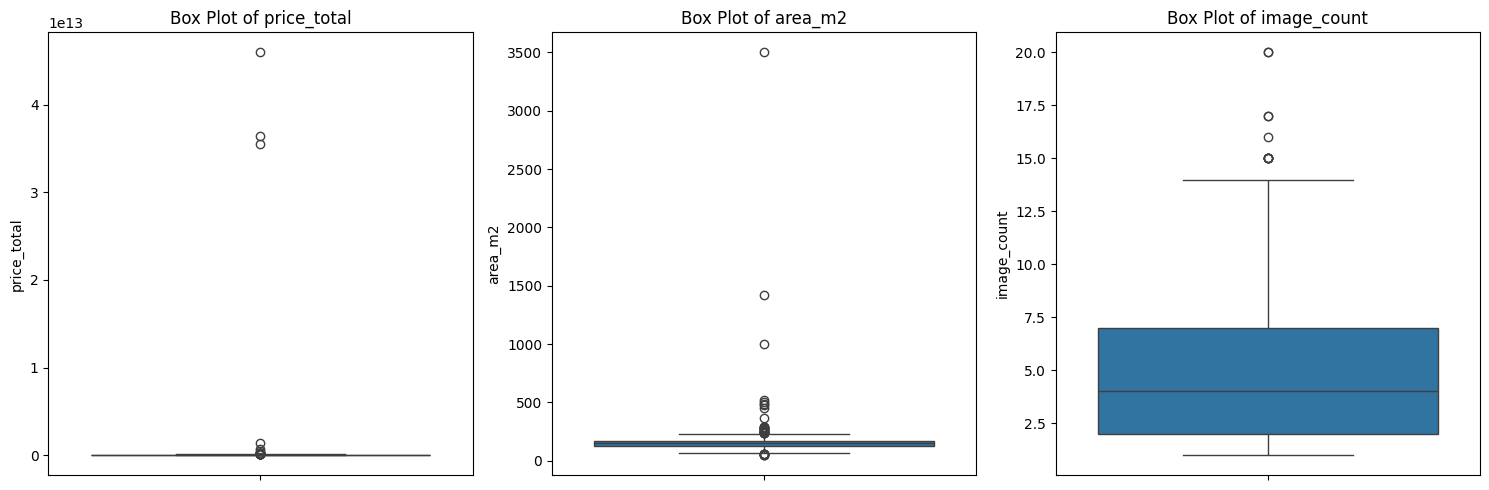

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

print("\n--- Visualizing Outliers (Box Plots for IQR) ---")

# Select columns with identified outliers for visualization
# Focusing on 'price_total' and 'area_m2' as they had significant outliers
columns_to_plot = ['price_total', 'area_m2', 'image_count']

plt.figure(figsize=(15, 5))
for i, col in enumerate(columns_to_plot):
    if col in df.columns and not df[col].dropna().empty:
        plt.subplot(1, len(columns_to_plot), i + 1)
        sns.boxplot(y=df[col].dropna())
        plt.title(f'Box Plot of {col}')
        plt.ylabel(col)
    else:
        print(f"Skipping visualization for '{col}' as it's not in DataFrame or has no data.")

plt.tight_layout()
plt.show()

**Reasoning**:
The previous step visualized outliers using box plots for the IQR method. Now, I will visualize outliers detected by the Z-score method using scatter plots for the same columns, adding horizontal lines to represent the Z-score threshold for better visual identification.




--- Visualizing Outliers (Scatter Plots for Z-score) ---


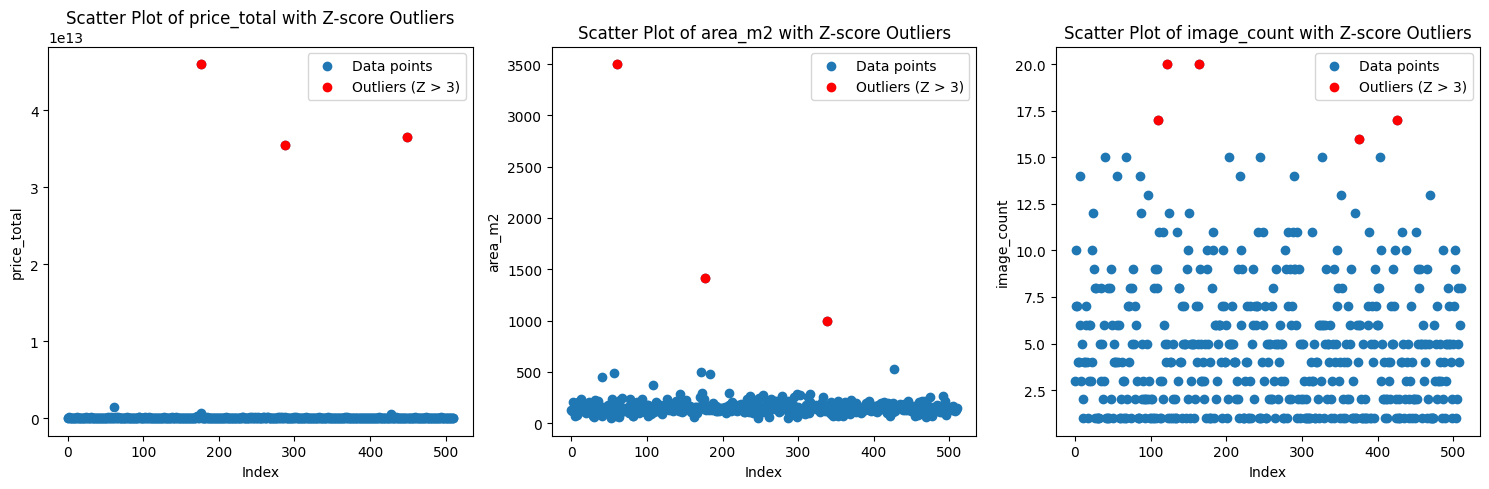

In [7]:
print("\n--- Visualizing Outliers (Scatter Plots for Z-score) ---")

plt.figure(figsize=(15, 5))
for i, col in enumerate(columns_to_plot):
    clean_data = df[col].dropna()
    if not clean_data.empty:
        plt.subplot(1, len(columns_to_plot), i + 1)

        # Calculate Z-scores for the current column
        z_scores = np.abs(stats.zscore(clean_data))

        # Create a scatter plot
        plt.scatter(clean_data.index, clean_data, label='Data points')

        # Highlight outliers
        outlier_indices = clean_data[z_scores > 3.0].index
        plt.scatter(outlier_indices, clean_data.loc[outlier_indices], color='red', label='Outliers (Z > 3)')

        # Add threshold lines (conceptual, actual Z-score is on a different scale, but useful for context)
        # Note: Visualizing Z-score directly on a scatter plot of original data values requires careful interpretation
        # This plot is more about showing the data points that were identified as outliers by Z-score.

        plt.title(f'Scatter Plot of {col} with Z-score Outliers')
        plt.xlabel('Index')
        plt.ylabel(col)
        plt.legend()
    else:
        print(f"Skipping visualization for '{col}' as it's not in DataFrame or has no data.")

plt.tight_layout()
plt.show()

## Summarize Findings

### Subtask:
Summarize the findings from the outlier detection process, comparing the results obtained using the Z-score and IQR methods. Discuss the differences in the number of outliers detected by each method and potential reasons for these discrepancies.

### Summary of Outlier Detection Findings

**Comparison of Z-score vs. IQR Methods:**

- **`city_id`**, **`rooms`**, **`lat`**, **`lng`**, **`location_radius`**: Both methods consistently found no outliers for these columns. This suggests that the data in these columns is relatively concentrated and does not contain extreme values that fall outside typical ranges for either statistical measure.

- **`unit_condition`**, **`direction`**, **`has_balcony`**: For these columns, there was no data available after dropping NaN values, so no outlier detection could be performed by either method.

- **`price_total`**:
    - **Z-score (threshold |Z| > 3)**: Detected 3 outliers.
    - **IQR (threshold 1.5 * IQR)**: Detected 33 outliers.
    - **Discrepancy**: The IQR method identified significantly more outliers than the Z-score method. This indicates that `price_total` likely has a skewed distribution or contains a substantial number of moderately extreme values that are considered outliers by the IQR's less restrictive boundary but not by the Z-score's assumption of normality.

- **`area_m2`**:
    - **Z-score (threshold |Z| > 3)**: Detected 3 outliers.
    - **IQR (threshold 1.5 * IQR)**: Detected 37 outliers.
    - **Discrepancy**: Similar to `price_total`, the IQR method found many more outliers in `area_m2`. This suggests that the distribution of `area_m2` is also likely skewed, with several data points falling beyond the 1.5 IQR fences but not being extreme enough to exceed a 3 standard deviation threshold from the mean.

- **`image_count`**:
    - **Z-score (threshold |Z| > 3)**: Detected 5 outliers.
    - **IQR (threshold 1.5 * IQR)**: Detected 11 outliers.
    - **Discrepancy**: The IQR method detected more outliers than the Z-score method, though the difference is less pronounced compared to `price_total` and `area_m2`. This implies that `image_count` might also have some skewness or a higher number of moderately extreme values.

**Key Observations and Reasons for Discrepancies:**

1.  **Sensitivity to Distribution**: The Z-score method assumes a normal distribution for the data. It is highly sensitive to the mean and standard deviation, and a few very extreme values can inflate the standard deviation, making other potentially anomalous points appear less extreme. The warning about 'Precision loss occurred in moment calculation due to catastrophic cancellation' further suggests that some columns might have very similar data points or a lack of variability, affecting Z-score reliability.

2.  **Robustness to Skewness**: The IQR method, being based on quartiles, is more robust to skewed distributions and extreme values. It identifies outliers as data points falling outside the `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]` range. This range is often narrower than the typical `mean ± 3*std_dev` range for non-normal distributions, leading to more detected outliers, especially in skewed data.

3.  **Nature of Data**: For real estate data like `price_total` and `area_m2`, it's common to see a skewed distribution with a long tail of very high values (luxury properties, large areas). In such cases, the IQR method provides a more practical definition of what constitutes an 'outlier' from the bulk of the data, while the Z-score method might only catch the most astronomically high values.

### Summary of Outlier Detection Findings

**Comparison of Z-score vs. IQR Methods:**

- **`city_id`**, **`rooms`**, **`lat`**, **`lng`**, **`location_radius`**: Both methods consistently found no outliers for these columns. This suggests that the data in these columns is relatively concentrated and does not contain extreme values that fall outside typical ranges for either statistical measure.

- **`unit_condition`**, **`direction`**, **`has_balcony`**: For these columns, there was no data available after dropping NaN values, so no outlier detection could be performed by either method.

- **`price_total`**:
    - **Z-score (threshold |Z| > 3)**: Detected 3 outliers.
    - **IQR (threshold 1.5 * IQR)**: Detected 33 outliers.
    - **Discrepancy**: The IQR method identified significantly more outliers than the Z-score method. This indicates that `price_total` likely has a skewed distribution or contains a substantial number of moderately extreme values that are considered outliers by the IQR's less restrictive boundary but not by the Z-score's assumption of normality.

- **`area_m2`**:
    - **Z-score (threshold |Z| > 3)**: Detected 3 outliers.
    - **IQR (threshold 1.5 * IQR)**: Detected 37 outliers.
    - **Discrepancy**: Similar to `price_total`, the IQR method found many more outliers in `area_m2`. This suggests that the distribution of `area_m2` is also likely skewed, with several data points falling beyond the 1.5 IQR fences but not being extreme enough to exceed a 3 standard deviation threshold from the mean.

- **`image_count`**:
    - **Z-score (threshold |Z| > 3)**: Detected 5 outliers.
    - **IQR (threshold 1.5 * IQR)**: Detected 11 outliers.
    - **Discrepancy**: The IQR method detected more outliers than the Z-score method, though the difference is less pronounced compared to `price_total` and `area_m2`. This implies that `image_count` might also have some skewness or a higher number of moderately extreme values.

**Key Observations and Reasons for Discrepancies:**

1.  **Sensitivity to Distribution**: The Z-score method assumes a normal distribution for the data. It is highly sensitive to the mean and standard deviation, and a few very extreme values can inflate the standard deviation, making other potentially anomalous points appear less extreme. The warning about 'Precision loss occurred in moment calculation due to catastrophic cancellation' further suggests that some columns might have very similar data points or a lack of variability, affecting Z-score reliability.

2.  **Robustness to Skewness**: The IQR method, being based on quartiles, is more robust to skewed distributions and extreme values. It identifies outliers as data points falling outside the `[Q1 - 1.5*IQR, Q3 + 1.5*IQR]` range. This range is often narrower than the typical `mean \u00b1 3*std_dev` range for non-normal distributions, leading to more detected outliers, especially in skewed data.

3.  **Nature of Data**: For real estate data like `price_total` and `area_m2`, it's common to see a skewed distribution with a long tail of very high values (luxury properties, large areas). In such cases, the IQR method provides a more practical definition of what constitutes an 'outlier' from the bulk of the data, while the Z-score method might only catch the most astronomically high values.


## Summary:

### Data Analysis Key Findings
*   The dataset `divar_dataset.csv` was successfully loaded, containing columns such as `price_total`, `area_m2`, and `image_count`.
*   Numeric columns identified for outlier analysis were `city_id`, `price_total`, `area_m2`, `rooms`, `unit_condition`, `direction`, `has_balcony`, `lat`, `lng`, `location_radius`, and `image_count`.
*   For columns `city_id`, `rooms`, `lat`, `lng`, and `location_radius`, both Z-score ($|Z| > 3$) and IQR (1.5 \* IQR) methods consistently found no outliers.
*   Columns `unit_condition`, `direction`, and `has_balcony` had no data available after dropping missing values, thus no outlier detection was performed for them.
*   The IQR method detected significantly more outliers than the Z-score method for highly skewed data:
    *   `price_total`: Z-score detected 3 outliers, while IQR detected 33 outliers.
    *   `area_m2`: Z-score detected 3 outliers, while IQR detected 37 outliers.
    *   `image_count`: Z-score detected 5 outliers, while IQR detected 11 outliers.
*   The visualization using box plots (for IQR) and scatter plots (for Z-score) confirmed these discrepancies, especially for `price_total` and `area_m2`.
*   The Z-score method's sensitivity to normal distribution and extreme values, along with its reliance on mean and standard deviation, resulted in fewer detected outliers compared to the IQR method, which is more robust to skewed distributions and uses quartiles.

### Insights or Next Steps
*   **Insight:** The choice of outlier detection method is crucial and should align with the data's distribution characteristics. For skewed data typical in real estate (e.g., prices, areas), the IQR method often provides a more realistic identification of values deviating from the central tendency.
*   **Next Step:** Further investigate the nature of the detected outliers. Determine if they represent data errors, rare but legitimate observations, or anomalies that require specific handling (e.g., capping, transformation, or removal) to avoid skewing downstream analyses or models.
